# NASAA V5 — Degradation Trend-Augmented GRU (DTA-GRU)

**Dataset:** NASA C-MAPSS FD001  
**Task:** Remaining Useful Life (RUL) prediction  
**Baseline:** Original 14-sensor GRU from V2  
**Proposed method:** Add causal sensor-velocity features and a late-life-weighted asymmetric regression loss.  

## Experimental story

1. Explore the C-MAPSS data and construct the capped RUL target.
2. Perform sensor-level EDA and causal feature engineering.
3. Preserve the same 14 raw sensor channels used by the original V2 GRU.
4. Build a trend-augmented input by appending a 5-cycle smoothed sensor derivative to each raw sensor.
5. Keep the GRU architecture unchanged.
6. Compare three controlled experiments: pure GRU, trend-augmented GRU, and DTA-GRU (trend inputs plus proposed loss).
7. Evaluate on the official test set only after model choices are frozen.

> **Research integrity:** DTA-GRU is a proposed training/input formulation, not a proven improvement. The notebook tests it against the pure GRU on the same split, windows, validation cutoffs, architecture and training budget. Report actual results even if the proposed method loses.

### Proposed algorithm in one line

For each sensor `s`, create a causal degradation-velocity feature:

\[
v_{s,t}=\frac{1}{5}\sum_{j=0}^{4}(x_{s,t-j}-x_{s,t-j-1})
\]

Then feed `[raw sensors, smoothed sensor velocities]` to the same GRU. Train the proposed version using a weighted asymmetric Smooth-L1 loss that gives somewhat more importance to low-RUL examples and overprediction errors.

No attention, no BiLSTM, and no additional recurrent architecture are used.

In [1]:
import copy
import json
import random
import joblib
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# ------------------------- Reproducibility -------------------------
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# ------------------------- Runtime -------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------- Plot style -------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300

# ------------------------- Experiment configuration -------------------------
SUBSET = "FD001"
RUL_CAP = 125
WINDOW_SIZE = 30
TOP_K_SENSORS = 14
VALIDATION_RUL_POINTS = [20, 50, 80, 110]
BATCH_SIZE = 128
MAX_EPOCHS = 50
PATIENCE = 8
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.2
LEARNING_RATE = 0.002
WEIGHT_DECAY = 1e-4

# Change this path to the folder containing train_FD001.txt,
# test_FD001.txt, and RUL_FD001.txt.
# Example Colab path: Path("/content/drive/MyDrive/CMaps")
DATA_DIR = Path(r"D:\ML_project\extracted\CMaps")

OUTPUT_DIR = Path("outputs_DTA_GRU")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())

Device: cpu
Output directory: D:\ML_project\outputs_DTA_GRU


## 2. Load NASA C-MAPSS FD001

The three expected files are `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt`. If using Colab, mount Google Drive first and update `DATA_DIR`.

In [2]:
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

read_options = {"sep": r"\s+", "header": None, "names": columns}

train_path = DATA_DIR / f"train_{SUBSET}.txt"
test_path = DATA_DIR / f"test_{SUBSET}.txt"
rul_path = DATA_DIR / f"RUL_{SUBSET}.txt"

for path in (train_path, test_path, rul_path):
    if not path.exists():
        raise FileNotFoundError(
            f"File not found: {path}\n"
            "Update DATA_DIR so it points to the folder containing the three C-MAPSS files."
        )

train_df = pd.read_csv(train_path, **read_options)
test_df = pd.read_csv(test_path, **read_options)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])

sensor_columns = [f"sensor_{i}" for i in range(1, 22)]
setting_columns = [f"op_setting_{i}" for i in range(1, 4)]
original_features = ["cycle"] + setting_columns + sensor_columns

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Official test RUL shape:", rul_df.shape)

display(train_df.head())
display(test_df.head())
display(rul_df.head())

Training shape: (20631, 26)
Test shape: (13096, 26)
Official test RUL shape: (100, 1)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,RUL
0,112
1,98
2,69
3,82
4,91


## 3. Data quality checks and RUL target construction

For each complete training engine, raw RUL equals its final observed cycle minus the current cycle. We use the same piecewise-linear target convention as V2: values above 125 are capped at 125.

The official test RUL file gives remaining life at the **last observed test cycle**. We use it only in the final test section.

In [3]:
# ------------------------- Data quality -------------------------
train_df = train_df.sort_values(["unit", "cycle"]).reset_index(drop=True)
test_df = test_df.sort_values(["unit", "cycle"]).reset_index(drop=True)

for name, frame in [("train", train_df), ("test", test_df)]:
    print(f"\\n{name.upper()} DATA")
    print("Missing values:", int(frame.isna().sum().sum()))
    print("Duplicate rows:", int(frame.duplicated().sum()))
    print("Unique engines:", frame["unit"].nunique())
    print("Cycle range:", int(frame["cycle"].min()), "to", int(frame["cycle"].max()))
    assert frame[["unit", "cycle"]].notna().all().all()

assert train_df.groupby("unit")["cycle"].apply(lambda x: x.is_monotonic_increasing).all()
assert len(rul_df) == test_df["unit"].nunique(), "Test engine count and RUL label count differ."

# ------------------------- Training labels -------------------------
train_df = train_df.sort_values(["unit", "cycle"]).reset_index(drop=True)
train_last_cycle = train_df.groupby("unit")["cycle"].max()
train_df["RUL_raw"] = train_df["unit"].map(train_last_cycle) - train_df["cycle"]
train_df["RUL"] = train_df["RUL_raw"].clip(upper=RUL_CAP)

print("\\nRaw training RUL summary:")
display(train_df["RUL_raw"].describe().to_frame())
print("Capped training RUL summary:")
display(train_df["RUL"].describe().to_frame())
display(train_df[["unit", "cycle", "RUL_raw", "RUL"]].head(10))

assert train_df["RUL"].min() == 0
assert train_df["RUL"].max() <= RUL_CAP

\nTRAIN DATA
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Cycle range: 1 to 362
\nTEST DATA
Missing values: 0
Duplicate rows: 0
Unique engines: 100
Cycle range: 1 to 303
\nRaw training RUL summary:


,RUL_raw
count,20631.000000
mean,107.807862
std,68.880990
min,0.000000
25%,51.000000
50%,103.000000
75%,155.000000
max,361.000000


Capped training RUL summary:


,RUL
count,20631.000000
mean,86.829286
std,41.673699
min,0.000000
25%,51.000000
50%,103.000000
75%,125.000000
max,125.000000


,unit,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


## 4. Exploratory data analysis (EDA)

These figures are designed to be reusable in the presentation. Each plot is also saved as a 300-DPI PNG under `outputs_DTA_GRU/figures/`.

Saved: outputs_DTA_GRU\figures\01_engine_life_and_rul_distribution.png


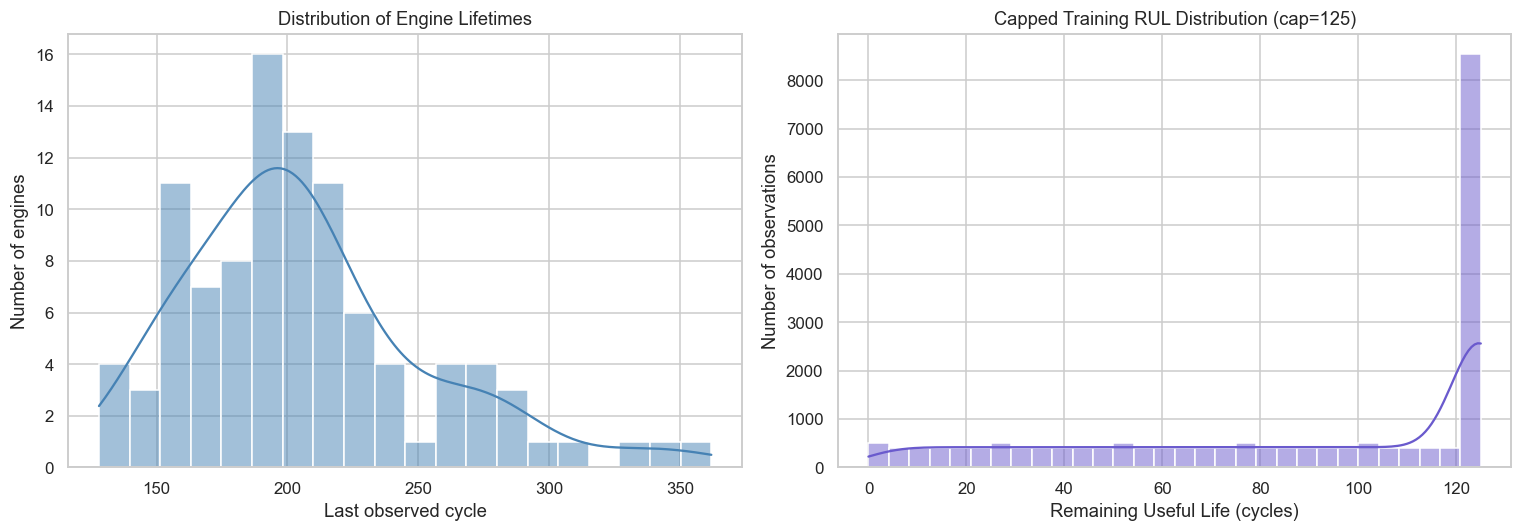

Saved: outputs_DTA_GRU\figures\02_piecewise_rul_target.png


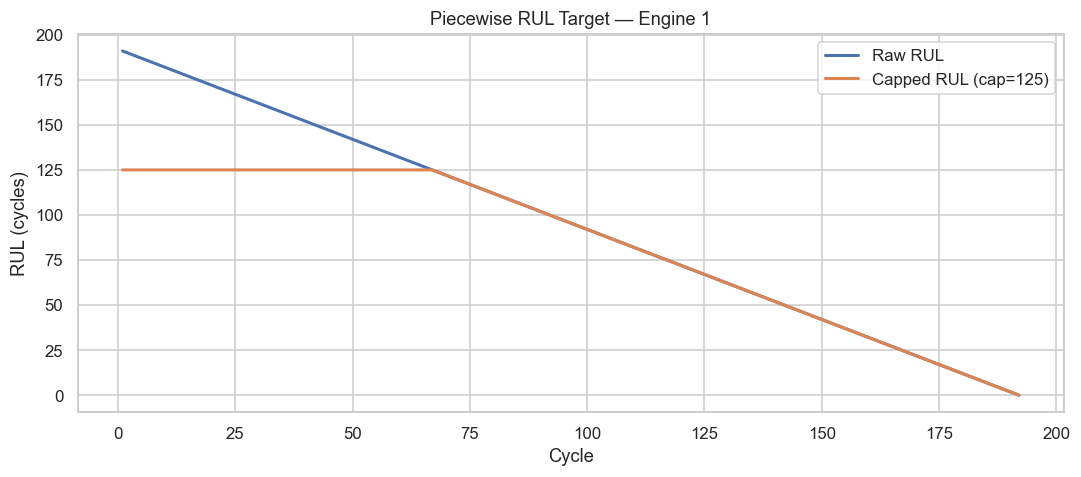

Saved: outputs_DTA_GRU\figures\03_sensor_correlation_heatmap.png


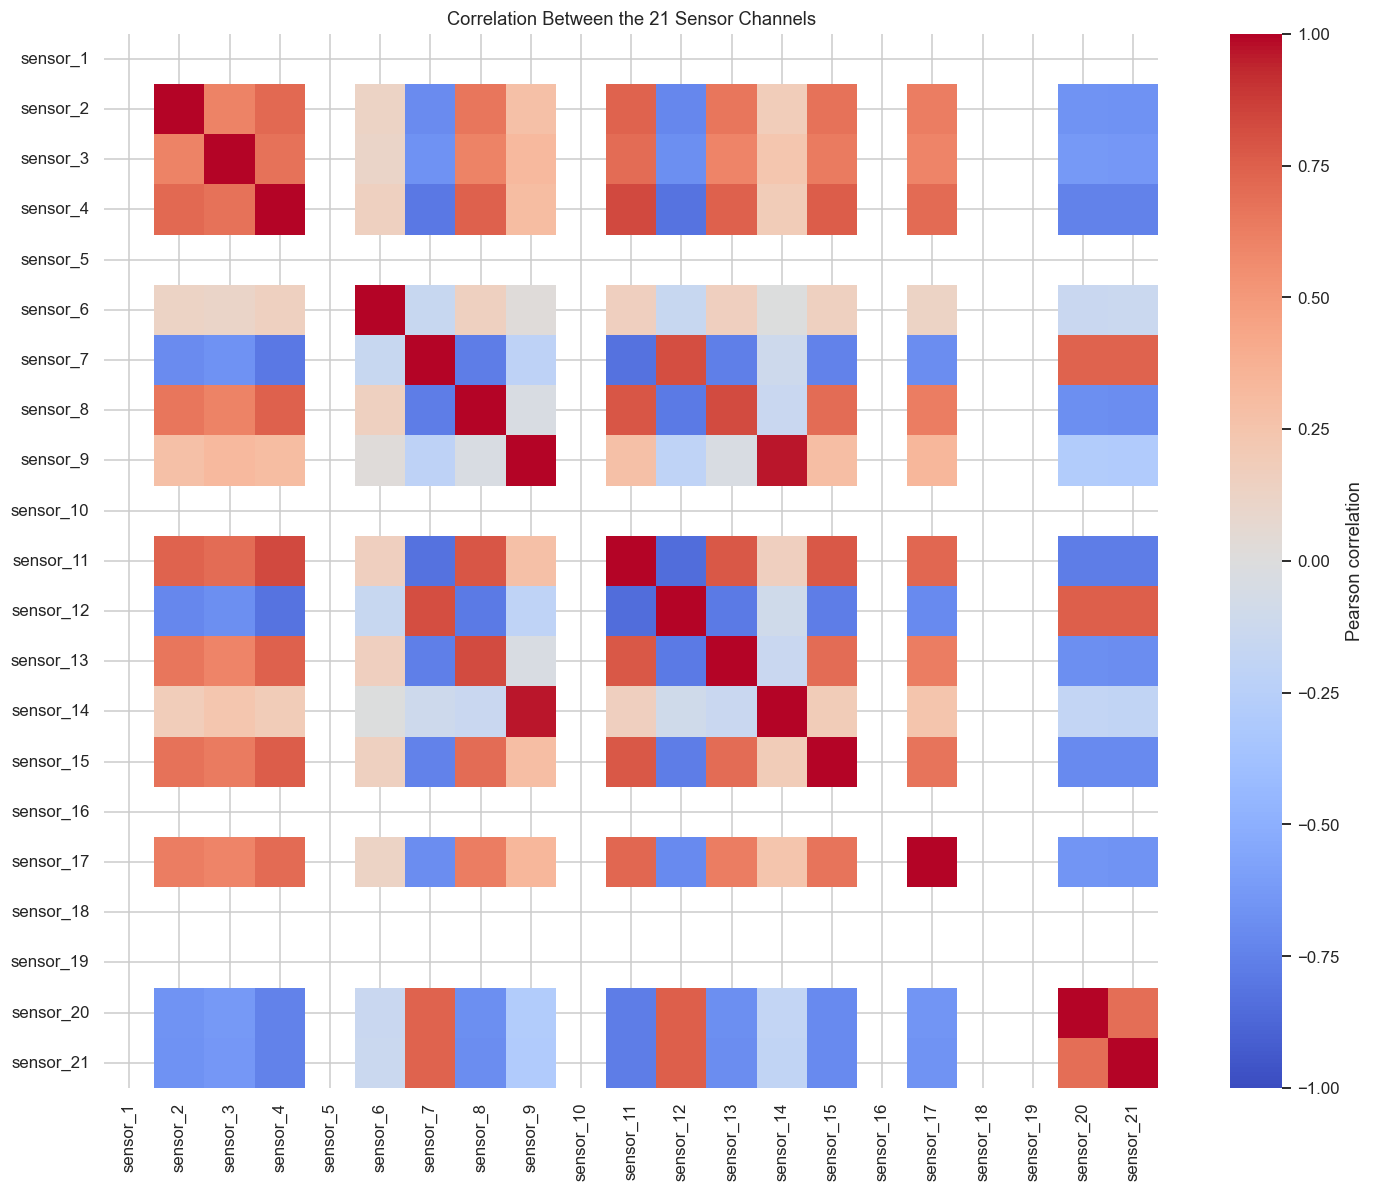

Saved: outputs_DTA_GRU\figures\04_sensor_variability.png


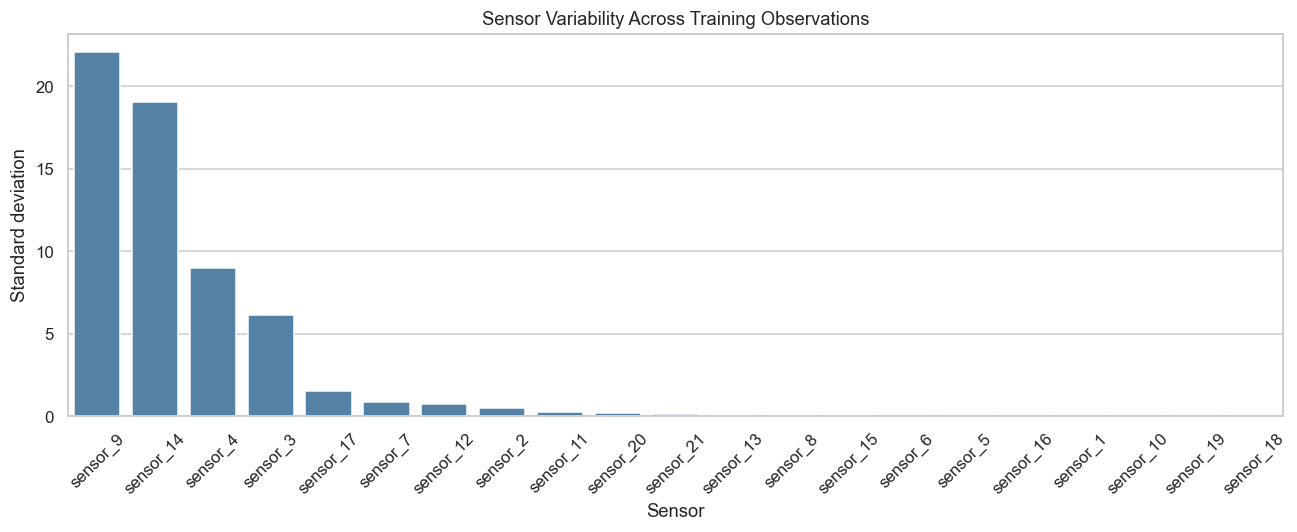

Engine count: 100
Sensor count: 21
Operating setting count: 3


In [4]:
def save_show(fig, filename):
    """Save a presentation-quality figure and display it in the notebook."""
    fig.tight_layout()
    save_path = FIGURE_DIR / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    print("Saved:", save_path)
    plt.show()

# Figure 1: engine life and RUL target distributions
engine_life = train_df.groupby("unit")["cycle"].max()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(engine_life, bins=20, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of Engine Lifetimes")
axes[0].set_xlabel("Last observed cycle")
axes[0].set_ylabel("Number of engines")

sns.histplot(train_df["RUL"], bins=30, kde=True, color="slateblue", ax=axes[1])
axes[1].set_title(f"Capped Training RUL Distribution (cap={RUL_CAP})")
axes[1].set_xlabel("Remaining Useful Life (cycles)")
axes[1].set_ylabel("Number of observations")

save_show(fig, "01_engine_life_and_rul_distribution.png")

# Figure 2: raw and capped RUL for one representative engine
sample_unit = int(train_df["unit"].iloc[0])
sample_engine = train_df[train_df["unit"] == sample_unit]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sample_engine["cycle"], sample_engine["RUL_raw"], label="Raw RUL", linewidth=2)
ax.plot(sample_engine["cycle"], sample_engine["RUL"], label=f"Capped RUL (cap={RUL_CAP})", linewidth=2)
ax.set_title(f"Piecewise RUL Target — Engine {sample_unit}")
ax.set_xlabel("Cycle")
ax.set_ylabel("RUL (cycles)")
ax.legend()
save_show(fig, "02_piecewise_rul_target.png")

# Figure 3: sensor correlation heatmap
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    train_df[sensor_columns].corr(),
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    square=True, ax=ax, cbar_kws={"label": "Pearson correlation"}
)
ax.set_title("Correlation Between the 21 Sensor Channels")
save_show(fig, "03_sensor_correlation_heatmap.png")

# Figure 4: sensor variability (useful for identifying almost-constant channels)
sensor_std = train_df[sensor_columns].std().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=sensor_std.index, y=sensor_std.values, color="steelblue", ax=ax)
ax.set_title("Sensor Variability Across Training Observations")
ax.set_xlabel("Sensor")
ax.set_ylabel("Standard deviation")
ax.tick_params(axis="x", rotation=45)
save_show(fig, "04_sensor_variability.png")

print("Engine count:", train_df["unit"].nunique())
print("Sensor count:", len(sensor_columns))
print("Operating setting count:", len(setting_columns))

## 5. Feature engineering — degradation velocity

The notebook still creates the familiar per-engine features for EDA:

- 5-cycle rolling mean and standard deviation.
- First difference and lags 1 and 3.
- EWMA with span 5.
- **5-cycle smoothed first difference (degradation velocity)** — the only engineered signal appended to the proposed GRU input.

All features are calculated within each engine, in cycle order, using only the current and earlier cycles. Therefore, the feature at cycle `t` does not use measurements after cycle `t`.

The pure-GRU baseline uses the original 14 raw sensors. The proposed DTA-GRU uses those same 14 raw sensors plus their 14 smoothed velocity channels. This keeps sensor identity fixed and isolates the value of temporal trend information.

Original sensor count: 21
Engineered feature count: 147
Training shape after feature engineering: (20631, 175)
Test shape after feature engineering: (13096, 173)


,unit,cycle,sensor_2,sensor_2_rolling_mean_5,sensor_2_rolling_std_5,sensor_2_diff_1,sensor_2_lag_1,sensor_2_lag_3,sensor_2_ewma_5,sensor_2_velocity_5
0,1,1,641.82,641.820000,NaN,0.00,NaN,NaN,641.820000,0.000000
1,1,2,642.15,641.985000,0.233345,0.33,641.82,NaN,641.930000,0.165000
2,1,3,642.35,642.106667,0.267644,0.20,642.15,NaN,642.070000,0.176667
3,1,4,642.35,642.167500,0.250117,0.00,642.35,641.82,642.163333,0.132500
4,1,5,642.37,642.208000,0.234776,0.02,642.35,642.15,642.232222,0.110000
5,1,6,642.10,642.264000,0.128374,-0.27,642.37,642.35,642.188148,0.056000
6,1,7,642.48,642.330000,0.139463,0.38,642.10,642.35,642.285432,0.066000
7,1,8,642.56,642.372000,0.174270,0.08,642.48,642.37,642.376955,0.042000
8,1,9,642.12,642.326000,0.208519,-0.44,642.56,642.10,642.291303,-0.046000
9,1,10,641.71,642.194000,0.340705,-0.41,642.12,642.48,642.097535,-0.132000


Saved: outputs_DTA_GRU\figures\05_sensor_feature_engineering_example.png


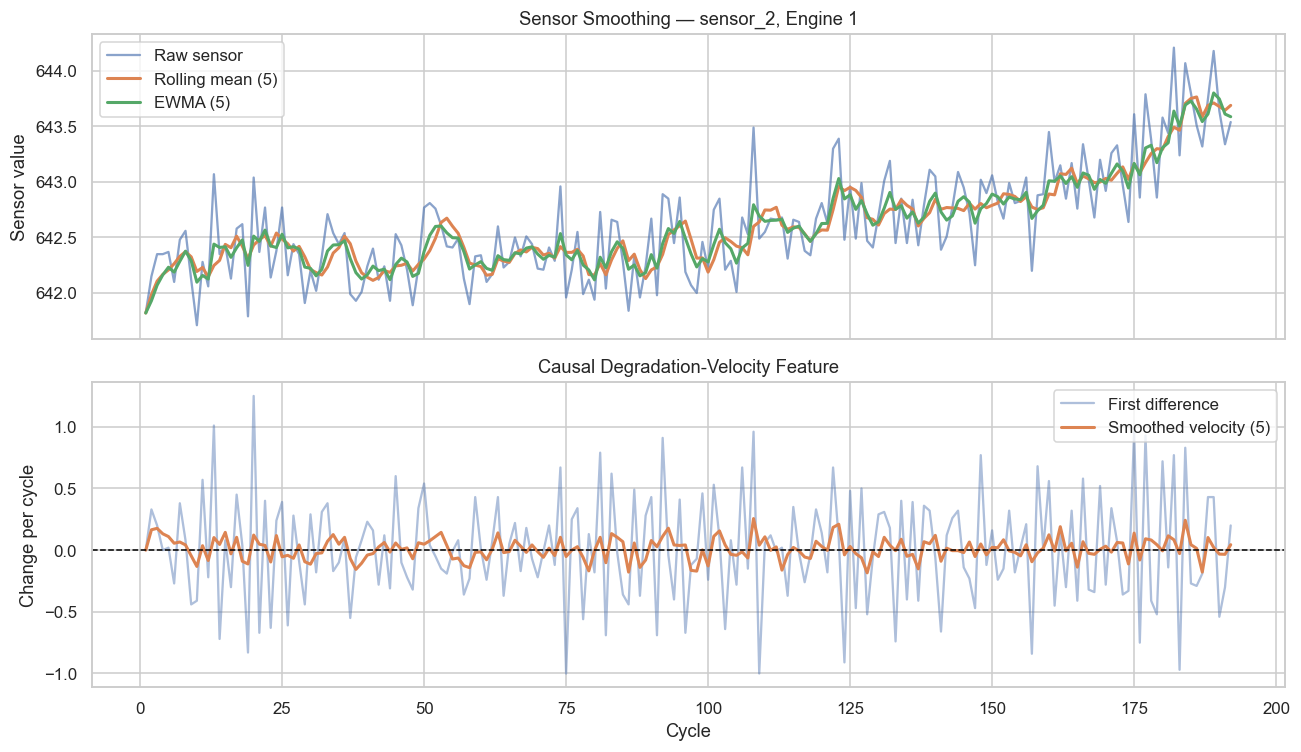

In [5]:
def add_sensor_features(data, sensors):
    data = data.sort_values(["unit", "cycle"]).copy()
    extra = {}

    for col in sensors:
        grouped = data.groupby("unit", sort=False)[col]
        delta = grouped.diff().fillna(0.0)

        extra[f"{col}_rolling_mean_5"] = grouped.transform(
            lambda x: x.rolling(window=5, min_periods=1).mean()
        )
        extra[f"{col}_rolling_std_5"] = grouped.transform(
            lambda x: x.rolling(window=5, min_periods=2).std()
        )
        extra[f"{col}_diff_1"] = delta
        extra[f"{col}_lag_1"] = grouped.shift(1)
        extra[f"{col}_lag_3"] = grouped.shift(3)
        extra[f"{col}_ewma_5"] = grouped.transform(
            lambda x: x.ewm(span=5, adjust=False).mean()
        )
        # Causal velocity: rolling average of current and previous cycle-to-cycle changes.
        extra[f"{col}_velocity_5"] = delta.groupby(data["unit"], sort=False).transform(
            lambda x: x.rolling(window=5, min_periods=1).mean()
        )

    engineered = pd.DataFrame(extra, index=data.index)
    return pd.concat([data, engineered], axis=1).copy()

train_features = add_sensor_features(train_df, sensor_columns)
test_features = add_sensor_features(test_df, sensor_columns)

engineered_feature_columns = [
    f"{sensor}_{suffix}"
    for sensor in sensor_columns
    for suffix in ["rolling_mean_5", "rolling_std_5", "diff_1", "lag_1", "lag_3", "ewma_5", "velocity_5"]
]

print("Original sensor count:", len(sensor_columns))
print("Engineered feature count:", len(engineered_feature_columns))
print("Training shape after feature engineering:", train_features.shape)
print("Test shape after feature engineering:", test_features.shape)

display(train_features[["unit", "cycle", "sensor_2"] + [
    "sensor_2_rolling_mean_5", "sensor_2_rolling_std_5",
    "sensor_2_diff_1", "sensor_2_lag_1", "sensor_2_lag_3",
    "sensor_2_ewma_5", "sensor_2_velocity_5"
]].head(10))

# Figure 5: raw sensor, smoothed trend, and first difference
feature_unit = int(train_df["unit"].iloc[0])
feature_sensor = "sensor_2"
feature_example = train_features[train_features["unit"] == feature_unit].sort_values("cycle")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(feature_example["cycle"], feature_example[feature_sensor], label="Raw sensor", alpha=0.65)
axes[0].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_rolling_mean_5"], label="Rolling mean (5)", linewidth=2)
axes[0].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_ewma_5"], label="EWMA (5)", linewidth=2)
axes[0].set_title(f"Sensor Smoothing — {feature_sensor}, Engine {feature_unit}")
axes[0].set_ylabel("Sensor value")
axes[0].legend()
axes[1].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_diff_1"], label="First difference", alpha=0.45)
axes[1].plot(feature_example["cycle"], feature_example[f"{feature_sensor}_velocity_5"], label="Smoothed velocity (5)", linewidth=2)
axes[1].axhline(0, linestyle="--", linewidth=1, color="black")
axes[1].set_title("Causal Degradation-Velocity Feature")
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel("Change per cycle")
axes[1].legend()
save_show(fig, "05_sensor_feature_engineering_example.png")

## 6. Engine-level training/validation split

We reserve 20% of engine IDs for validation. Every cycle belonging to an engine remains in the same partition. The official test engines are not involved in this split.

In [6]:
all_train_units = np.array(sorted(train_features["unit"].unique()))
rng_split = np.random.default_rng(SEED)
shuffled_units = rng_split.permutation(all_train_units)
num_val_units = max(1, int(round(0.20 * len(shuffled_units))))
val_units = np.sort(shuffled_units[:num_val_units])
train_units = np.sort(shuffled_units[num_val_units:])

train_part = train_features[train_features["unit"].isin(train_units)].copy()
val_part = train_features[train_features["unit"].isin(val_units)].copy()

print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))
print("Training rows:", len(train_part))
print("Validation rows:", len(val_part))
print("Engine overlap:", len(set(train_units) & set(val_units)))
assert len(set(train_units) & set(val_units)) == 0

Training engines: 80
Validation engines: 20
Training rows: 16779
Validation rows: 3852
Engine overlap: 0


## 7. Proposed algorithm — Degradation Trend-Augmented GRU (DTA-GRU)

DASI only changes which sensors are selected. It may discard a sensor that has useful short-term changes even if its full-life trend score is low. We instead preserve the original V2 14-sensor set and expose the local degradation rate to the GRU.

### 7.1 Causal sensor velocity

For each sensor `s`, calculate the one-cycle change and smooth it over the latest five cycles:

\[
\Delta x_{s,t}=x_{s,t}-x_{s,t-1}
\]

\[
v_{s,t}=\frac{1}{5}\sum_{j=0}^{4}\Delta x_{s,t-j}
\]

At the beginning of an engine trajectory, use the available history (`min_periods=1`). The grouped calculation resets at each engine boundary. No future readings are used.

### 7.2 Input representation

The baseline input is the original 14-sensor vector:

\[
z_t^{base}=[x_{1,t},\ldots,x_{14,t}]
\]

The proposed input appends 14 smoothed velocities:

\[
z_t^{DTA}=[x_{1,t},\ldots,x_{14,t},v_{1,t},\ldots,v_{14,t}]
\]

The GRU architecture and sequence length remain unchanged.

### 7.3 Late-life-weighted asymmetric loss

Let `e = prediction - target`. We use:

\[
w(y)=1+\lambda\left(1-\frac{y}{R_{max}}\right)^\gamma
\]

\[
L=\operatorname{mean}\left[w(y)\,a(e)\,\operatorname{SmoothL1}(e)\right]
\]

where `a(e)` is 1 for underprediction and a mild factor greater than 1 for overprediction. This reflects the higher cost of overestimating remaining life in the NASA scoring function. The late-life factor gives somewhat more importance to low-RUL training examples.

**This is a hypothesis to test, not a guaranteed improvement.** The notebook compares raw GRU, trend-only GRU, and the complete DTA-GRU separately so we can attribute any gain.

In [7]:
# Keep exactly the original 14 sensor channels from the V2 GRU.
baseline_sensors = [
    "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", "sensor_9",
    "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
    "sensor_17", "sensor_20", "sensor_21"
]

velocity_features = [f"{sensor}_velocity_5" for sensor in baseline_sensors]
proposed_features = baseline_sensors + velocity_features

print("Pure GRU input channels:", len(baseline_sensors))
print("DTA-GRU input channels:", len(proposed_features))
print("Raw channels:", baseline_sensors)
print("Velocity channels:", velocity_features)

# Keep an explicit feature specification for reproducibility.
feature_specification = pd.DataFrame({
    "feature": proposed_features,
    "type": ["raw_sensor"] * len(baseline_sensors) + ["smoothed_velocity_5"] * len(velocity_features)
})
display(feature_specification)
feature_specification.to_csv(OUTPUT_DIR / "dta_feature_specification.csv", index=False)

Pure GRU input channels: 14
DTA-GRU input channels: 28
Raw channels: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Velocity channels: ['sensor_2_velocity_5', 'sensor_3_velocity_5', 'sensor_4_velocity_5', 'sensor_7_velocity_5', 'sensor_8_velocity_5', 'sensor_9_velocity_5', 'sensor_11_velocity_5', 'sensor_12_velocity_5', 'sensor_13_velocity_5', 'sensor_14_velocity_5', 'sensor_15_velocity_5', 'sensor_17_velocity_5', 'sensor_20_velocity_5', 'sensor_21_velocity_5']


,feature,type
0,sensor_2,raw_sensor
1,sensor_3,raw_sensor
2,sensor_4,raw_sensor
3,sensor_7,raw_sensor
4,sensor_8,raw_sensor
5,sensor_9,raw_sensor
6,sensor_11,raw_sensor
7,sensor_12,raw_sensor
8,sensor_13,raw_sensor
9,sensor_14,raw_sensor


## 8. Proposed-feature visualizations

These figures explain what is added to the original GRU. They are computed from training-partition engines only.

Saved: outputs_DTA_GRU\figures\06_sensor_velocity_magnitude.png


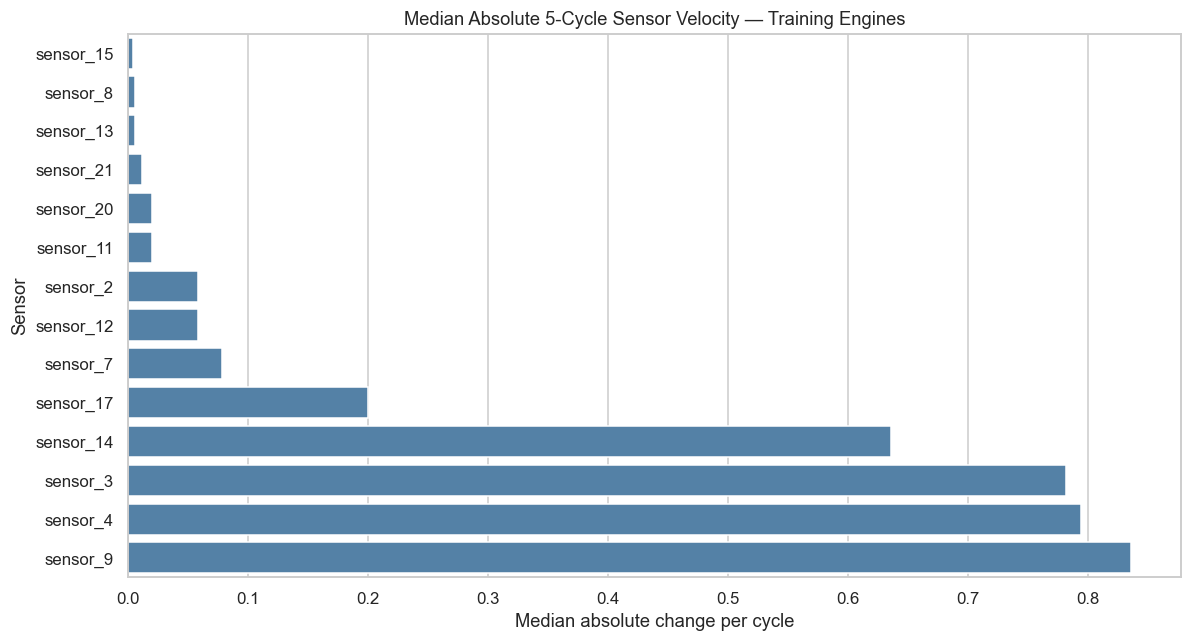

Saved: outputs_DTA_GRU\figures\07_raw_and_velocity_channels.png


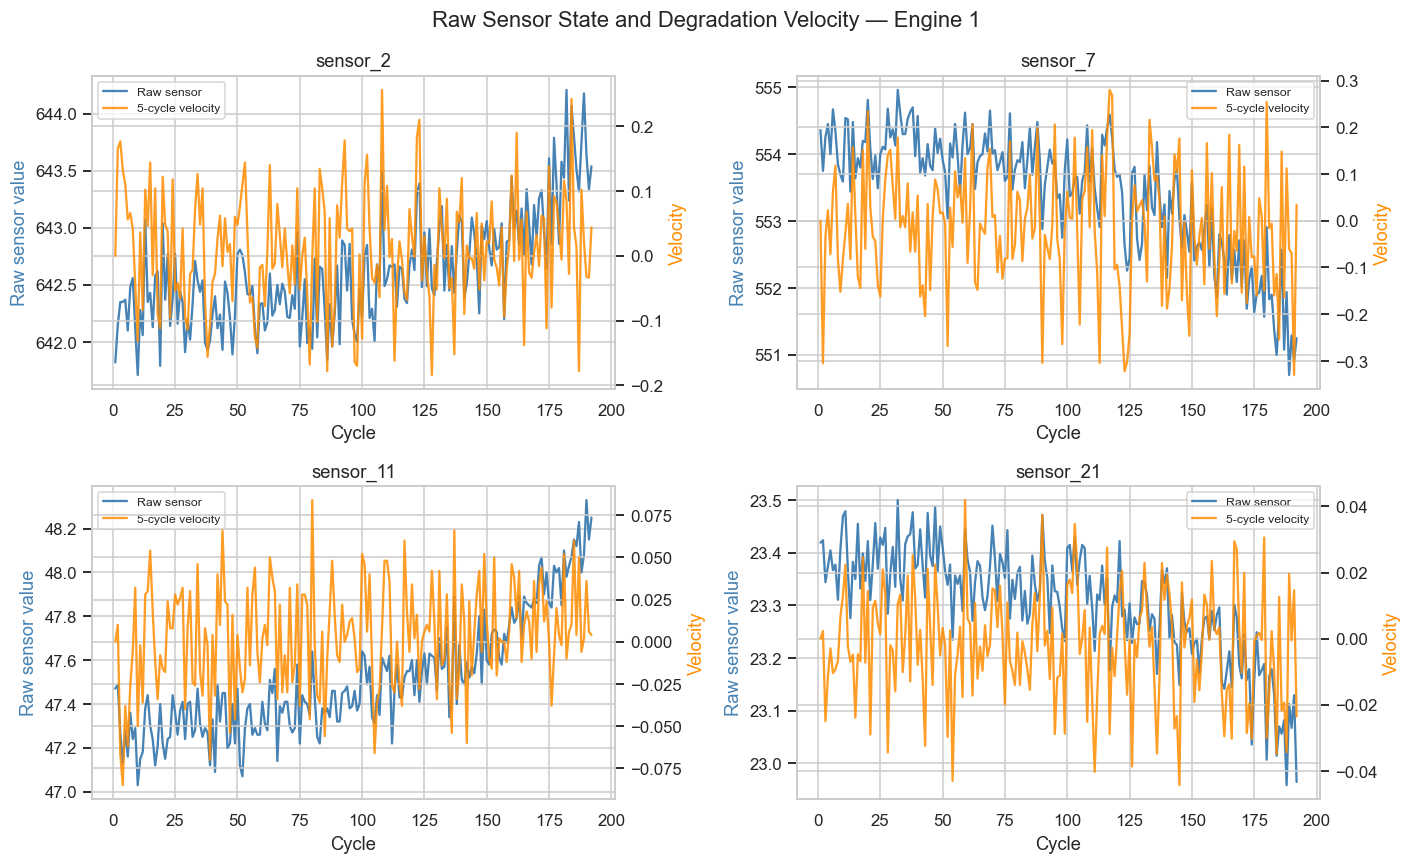

Saved: outputs_DTA_GRU\figures\08_dta_input_channel_map.png


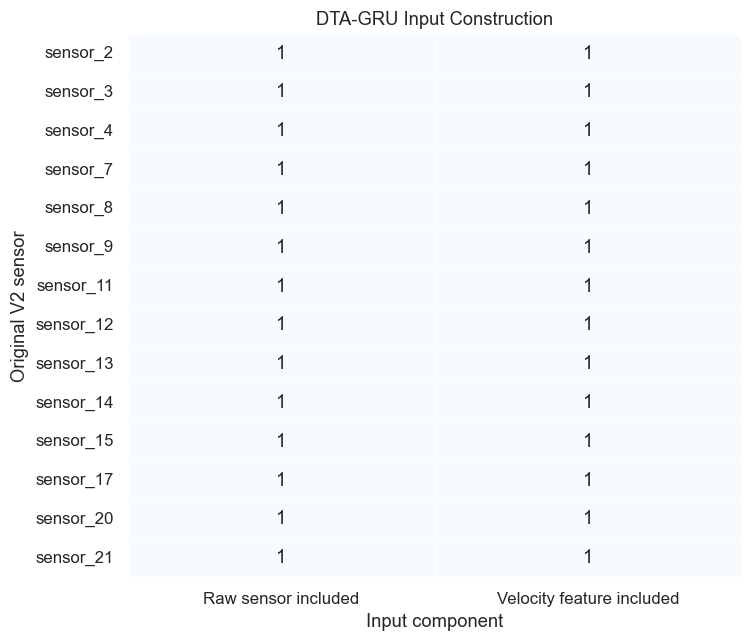

In [8]:
# Figure 6: distribution of per-sensor smoothed velocity magnitude
velocity_magnitude = pd.Series({
    sensor: train_part[f"{sensor}_velocity_5"].abs().median()
    for sensor in baseline_sensors
}).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=velocity_magnitude.values, y=velocity_magnitude.index, color="steelblue", ax=ax)
ax.set_title("Median Absolute 5-Cycle Sensor Velocity — Training Engines")
ax.set_xlabel("Median absolute change per cycle")
ax.set_ylabel("Sensor")
save_show(fig, "06_sensor_velocity_magnitude.png")

# Figure 7: raw and velocity trajectories for four representative input sensors
plot_sensors = ["sensor_2", "sensor_7", "sensor_11", "sensor_21"]
plot_unit = int(train_part["unit"].iloc[0])
engine_plot = train_part[train_part["unit"] == plot_unit].sort_values("cycle")
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, sensor in zip(axes.flat, plot_sensors):
    ax2 = ax.twinx()
    ax.plot(engine_plot["cycle"], engine_plot[sensor], label="Raw sensor", color="steelblue")
    ax2.plot(engine_plot["cycle"], engine_plot[f"{sensor}_velocity_5"], label="5-cycle velocity", color="darkorange", alpha=0.85)
    ax.set_title(sensor)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Raw sensor value", color="steelblue")
    ax2.set_ylabel("Velocity", color="darkorange")
    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [line.get_label() for line in lines], loc="best", fontsize=8)
fig.suptitle(f"Raw Sensor State and Degradation Velocity — Engine {plot_unit}")
save_show(fig, "07_raw_and_velocity_channels.png")

# Figure 8: input-channel map — every original sensor is retained; velocity is appended
input_map = pd.DataFrame({
    "Sensor": baseline_sensors,
    "Raw sensor included": 1,
    "Velocity feature included": 1
}).set_index("Sensor")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(input_map, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set_title("DTA-GRU Input Construction")
ax.set_xlabel("Input component")
ax.set_ylabel("Original V2 sensor")
save_show(fig, "08_dta_input_channel_map.png")

## 9. Build comparable validation examples

For every held-out validation engine, create observations at target RUL points 20, 50, 80 and 110 cycles (where enough history exists). Each example uses only the engine's history up to that cutoff. All three experiments use exactly the same examples.

Validation examples: 79
Validation engines represented: 20 / 20
Validation target distribution:


,actual_RUL
count,79.00000
mean,64.43038
std,33.57910
min,20.00000
25%,35.00000
50%,50.00000
75%,80.00000
max,110.00000


,unit,cutoff_cycle,actual_RUL_raw,actual_RUL
0,3,159,20.0,20.0
1,3,129,50.0,50.0
2,3,99,80.0,80.0
3,3,69,110.0,110.0
4,5,249,20.0,20.0


Saved: outputs_DTA_GRU\figures\09_validation_rul_stage_counts.png


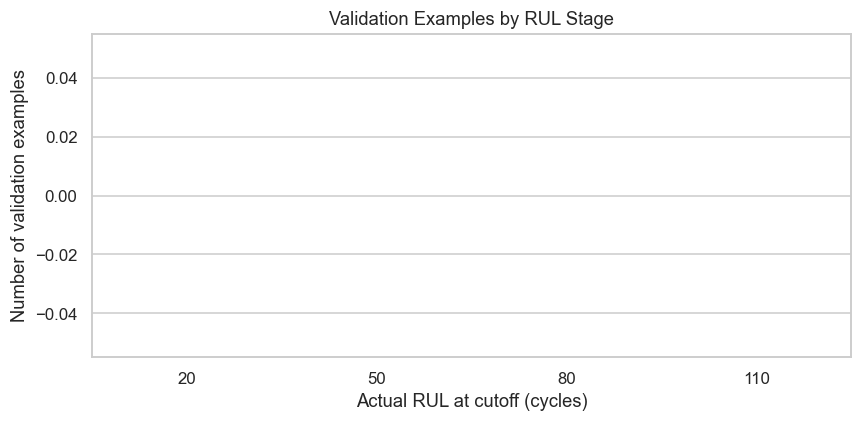

In [9]:
# Create a validation metadata table. RUL is exact here because training engines are run to failure.
validation_records = []
for unit in val_units:
    engine = val_part[val_part["unit"] == unit].sort_values("cycle")
    last_cycle = int(engine["cycle"].max())

    for target_rul in VALIDATION_RUL_POINTS:
        cutoff_cycle = last_cycle - int(target_rul)
        prefix = engine[engine["cycle"] <= cutoff_cycle]

        if len(prefix) < WINDOW_SIZE:
            continue

        validation_records.append({
            "unit": int(unit),
            "cutoff_cycle": int(cutoff_cycle),
            "actual_RUL_raw": float(target_rul),
            "actual_RUL": float(min(target_rul, RUL_CAP))
        })

val_meta = pd.DataFrame(validation_records)
if val_meta.empty:
    raise ValueError("No validation examples were created. Check WINDOW_SIZE and validation cutoffs.")

print("Validation examples:", len(val_meta))
print("Validation engines represented:", val_meta["unit"].nunique(), "/", len(val_units))
print("Validation target distribution:")
display(val_meta["actual_RUL"].describe().to_frame())
display(val_meta.head())

# Figure 9: validation sample counts across selected RUL stages
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=val_meta, x="actual_RUL", order=VALIDATION_RUL_POINTS, color="steelblue", ax=ax)
ax.set_title("Validation Examples by RUL Stage")
ax.set_xlabel("Actual RUL at cutoff (cycles)")
ax.set_ylabel("Number of validation examples")
save_show(fig, "09_validation_rul_stage_counts.png")

## 10. Sequence preparation and evaluation metrics

The imputer and scaler are fitted on unique training rows for each experiment's input channels. They are then applied to validation rows. This avoids fitting preprocessing on validation data or overweighting interior cycles because they occur in many overlapping windows.

In [10]:
def make_training_sequences(data, units, feature_columns, window_size):
    X, y = [], []

    for unit in units:
        engine = data[data["unit"] == unit].sort_values("cycle")
        values = engine[feature_columns].to_numpy(dtype=np.float32)
        targets = engine["RUL"].to_numpy(dtype=np.float32)

        if len(engine) < window_size:
            continue

        for end in range(window_size - 1, len(engine)):
            X.append(values[end - window_size + 1:end + 1])
            y.append(targets[end])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


def make_validation_sequences(data, metadata, feature_columns, window_size):
    X, y = [], []
    used_rows = []

    for row in metadata.itertuples(index=False):
        engine = data[
            (data["unit"] == row.unit) & (data["cycle"] <= row.cutoff_cycle)
        ].sort_values("cycle")

        if len(engine) < window_size:
            continue

        values = engine[feature_columns].to_numpy(dtype=np.float32)
        X.append(values[-window_size:])
        y.append(float(row.actual_RUL))
        used_rows.append({
            "unit": int(row.unit),
            "cutoff_cycle": int(row.cutoff_cycle),
            "actual_RUL": float(row.actual_RUL)
        })

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32), pd.DataFrame(used_rows)


def nasa_score(actual, predicted):
    """NASA asymmetric score; lower is better."""
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)
    error = predicted - actual
    penalties = np.where(error < 0, np.exp(-error / 13.0) - 1.0,
                         np.exp(error / 10.0) - 1.0)
    return float(np.sum(penalties))


def evaluate_rul(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.maximum(np.asarray(predicted, dtype=np.float64), 0.0)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "NASA Score": nasa_score(actual, predicted)
    }


def transform_frame(frame, feature_columns, imputer, scaler):
    out = frame[["unit", "cycle", "RUL"]].copy() if "RUL" in frame.columns else frame[["unit", "cycle"]].copy()
    values = imputer.transform(frame[feature_columns])
    values = scaler.transform(values)
    for idx, col in enumerate(feature_columns):
        out[col] = values[:, idx]
    return out

## 11. Original GRU architecture (unchanged)

The model is the same plain GRU design used in V2. It has no attention module, no BiLSTM, and no additional recurrent branch.

In [11]:
class GRURegressor(nn.Module):
    """The same plain two-layer GRU backbone used by the V2 baseline."""
    def __init__(self, input_size, hidden_size=HIDDEN_SIZE,
                 num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.output = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.gru(x)
        return self.output(out[:, -1, :]).squeeze(1)


class DegradationWeightedAsymmetricHuber(nn.Module):
    """Mild late-life weighting plus a larger penalty for RUL overprediction.

    Predictions and targets are standardized. The error direction is unchanged
    by standardization; the target is converted back to RUL units for stage weights.
    """
    def __init__(self, rul_cap=RUL_CAP, late_life_boost=0.50,
                 gamma=1.0, overprediction_weight=1.25, beta=1.0):
        super().__init__()
        self.rul_cap = float(rul_cap)
        self.late_life_boost = float(late_life_boost)
        self.gamma = float(gamma)
        self.overprediction_weight = float(overprediction_weight)
        self.beta = float(beta)

    def forward(self, prediction_scaled, target_scaled, y_mean, y_std):
        error = prediction_scaled - target_scaled
        point_loss = F.smooth_l1_loss(
            prediction_scaled, target_scaled,
            reduction="none", beta=self.beta
        )

        target_rul = target_scaled * y_std + y_mean
        late_stage = (1.0 - target_rul / self.rul_cap).clamp(0.0, 1.0)
        stage_weight = 1.0 + self.late_life_boost * late_stage.pow(self.gamma)
        direction_weight = torch.where(
            error > 0,
            torch.as_tensor(self.overprediction_weight, device=error.device, dtype=error.dtype),
            torch.ones_like(error)
        )
        return (point_loss * stage_weight * direction_weight).mean()


def train_gru_experiment(experiment_name, feature_columns, use_dta_loss=False):
    """Train a GRU variant under identical split, windows and validation examples."""
    seed_everything(SEED)

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    train_imputed = imputer.fit_transform(train_part[feature_columns])
    scaler.fit(train_imputed)

    train_scaled = transform_frame(train_part, feature_columns, imputer, scaler)
    val_scaled = transform_frame(val_part, feature_columns, imputer, scaler)

    X_train, y_train = make_training_sequences(
        train_scaled, train_units, feature_columns, WINDOW_SIZE
    )
    X_val, y_val, val_meta_used = make_validation_sequences(
        val_scaled, val_meta, feature_columns, WINDOW_SIZE
    )
    if len(X_train) == 0 or len(X_val) == 0:
        raise ValueError(f"No sequence data available for {experiment_name}.")

    y_mean = float(y_train.mean())
    y_std = float(y_train.std() + 1e-8)
    y_train_scaled = (y_train - y_mean) / y_std

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train_scaled, dtype=torch.float32)
    )
    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=loader_generator, num_workers=0
    )

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
    model = GRURegressor(input_size=len(feature_columns)).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )
    custom_loss = DegradationWeightedAsymmetricHuber() if use_dta_loss else None

    best_rmse = float("inf")
    best_state = None
    best_epoch = 0
    patience_counter = 0
    history = []

    print(f"\nTraining: {experiment_name}")
    print("Input shape:", X_train.shape, "| Validation shape:", X_val.shape)

    for epoch in range(1, MAX_EPOCHS + 1):
        lr_used = float(optimizer.param_groups[0]["lr"])
        model.train()
        running_loss = 0.0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad(set_to_none=True)
            predictions = model(batch_X)

            if custom_loss is None:
                loss = F.smooth_l1_loss(predictions, batch_y)
            else:
                loss = custom_loss(predictions, batch_y, y_mean, y_std)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += float(loss.item())

        train_loss = running_loss / max(len(train_loader), 1)
        model.eval()
        with torch.no_grad():
            val_scaled_predictions = model(X_val_tensor).cpu().numpy()

        val_predictions = np.clip(val_scaled_predictions * y_std + y_mean, 0.0, RUL_CAP)
        val_rmse = float(np.sqrt(mean_squared_error(y_val, val_predictions)))
        val_nasa = nasa_score(y_val, val_predictions)
        scheduler.step(val_rmse)
        history.append({
            "epoch": epoch, "train_loss": train_loss,
            "val_rmse": val_rmse, "val_nasa_score": val_nasa,
            "lr_used": lr_used
        })

        # Same checkpoint-selection metric for all experiments: validation RMSE.
        if val_rmse < best_rmse:
            best_rmse = val_rmse
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val RMSE: {val_rmse:.3f} | Val NASA: {val_nasa:.2f}"
            )

        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch}; best epoch = {best_epoch}")
            break

    if best_state is None:
        raise RuntimeError(f"Training failed to produce a checkpoint for {experiment_name}.")

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        val_scaled_predictions = model(X_val_tensor).cpu().numpy()

    val_predictions = np.clip(val_scaled_predictions * y_std + y_mean, 0.0, RUL_CAP)
    scores = evaluate_rul(y_val, val_predictions)

    return {
        "name": experiment_name,
        "features": list(feature_columns),
        "use_dta_loss": bool(use_dta_loss),
        "model": model,
        "imputer": imputer,
        "scaler": scaler,
        "y_mean": y_mean,
        "y_std": y_std,
        "best_epoch": best_epoch,
        "history": pd.DataFrame(history),
        "X_val": X_val,
        "y_val": y_val,
        "val_predictions": val_predictions,
        "val_meta": val_meta_used,
        "metrics": scores,
        "train_sequence_shape": X_train.shape
    }

## 12. Controlled ablation: pure GRU vs trend augmentation vs DTA-GRU

All three experiments use the same GRU architecture, training/validation engine split, sequence length, validation cutoffs, optimizer, stopping rule and checkpoint-selection metric.

- **E1 — Pure GRU:** 14 original sensors + standard Smooth-L1 loss.
- **E2 — Trend-Augmented GRU:** 14 raw sensors + 14 smoothed velocity channels + standard Smooth-L1 loss.
- **E3 — DTA-GRU:** the same 28 input channels as E2 + proposed late-life-weighted asymmetric loss.

This ablation separates the effect of the new input representation from the effect of the proposed loss.

In [12]:
baseline_result = train_gru_experiment(
    "Pure GRU (V2 baseline)", baseline_sensors, use_dta_loss=False
)
trend_result = train_gru_experiment(
    "Trend-Augmented GRU", proposed_features, use_dta_loss=False
)
dta_result = train_gru_experiment(
    "Proposed DTA-GRU", proposed_features, use_dta_loss=True
)

validation_results = pd.DataFrame([
    {"Model": baseline_result["name"], **baseline_result["metrics"]},
    {"Model": trend_result["name"], **trend_result["metrics"]},
    {"Model": dta_result["name"], **dta_result["metrics"]}
]).sort_values("RMSE").reset_index(drop=True)

print("Validation results — identical validation examples for all models:")
display(validation_results.round(4))

baseline_metrics = baseline_result["metrics"]
for label, result in [("Trend augmentation", trend_result), ("Full DTA-GRU", dta_result)]:
    print(f"\n{label} relative to pure GRU (positive improvement means lower metric):")
    for metric in ["RMSE", "MAE", "NASA Score"]:
        delta = baseline_metrics[metric] - result["metrics"][metric]
        print(f"{metric}: {delta:+.4f}")

validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)


Training: Pure GRU (V2 baseline)
Input shape: (14459, 30, 14) | Validation shape: (79, 30, 14)
Epoch 01/50 | Train loss: 0.1216 | Val RMSE: 18.761 | Val NASA: 1129.55
Epoch 05/50 | Train loss: 0.0443 | Val RMSE: 18.207 | Val NASA: 1518.16
Epoch 10/50 | Train loss: 0.0364 | Val RMSE: 16.454 | Val NASA: 805.39
Early stopping at epoch 10; best epoch = 2

Training: Trend-Augmented GRU
Input shape: (14459, 30, 28) | Validation shape: (79, 30, 28)
Epoch 01/50 | Train loss: 0.0952 | Val RMSE: 15.056 | Val NASA: 407.12
Epoch 05/50 | Train loss: 0.0137 | Val RMSE: 15.888 | Val NASA: 529.74
Early stopping at epoch 9; best epoch = 1

Training: Proposed DTA-GRU
Input shape: (14459, 30, 28) | Validation shape: (79, 30, 28)
Epoch 01/50 | Train loss: 0.1298 | Val RMSE: 14.080 | Val NASA: 327.96
Epoch 05/50 | Train loss: 0.0164 | Val RMSE: 15.480 | Val NASA: 524.07
Early stopping at epoch 9; best epoch = 1
Validation results — identical validation examples for all models:


,Model,RMSE,MAE,NASA Score
0,Proposed DTA-GRU,14.0802,10.1992,327.9604
1,Trend-Augmented GRU,15.0555,11.2830,407.1229
2,Pure GRU (V2 baseline),15.2603,10.5135,817.6382



Trend augmentation relative to pure GRU (positive improvement means lower metric):
RMSE: +0.2047
MAE: -0.7695
NASA Score: +410.5152

Full DTA-GRU relative to pure GRU (positive improvement means lower metric):
RMSE: +1.1801
MAE: +0.3143
NASA Score: +489.6777


## 13. Training and validation visualizations

The plots compare all three experiments. Use the same-split metric table as the primary evidence; do not compare it directly with an old score from a different validation protocol.

Saved: outputs_DTA_GRU\figures\10_training_curves.png


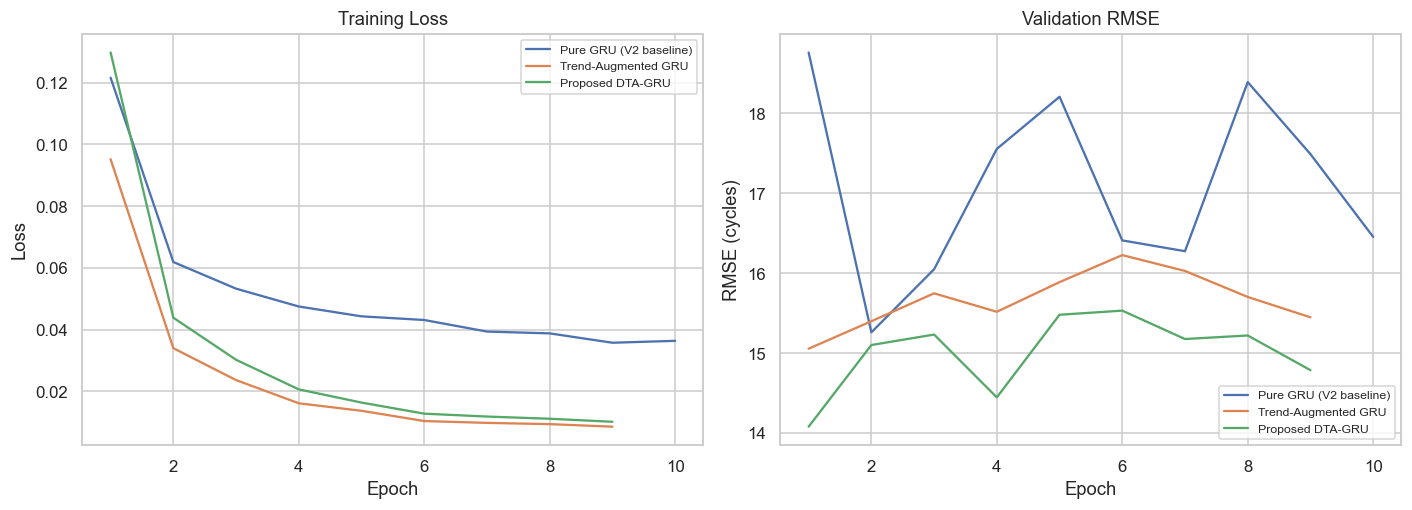

Saved: outputs_DTA_GRU\figures\11_validation_metric_comparison.png


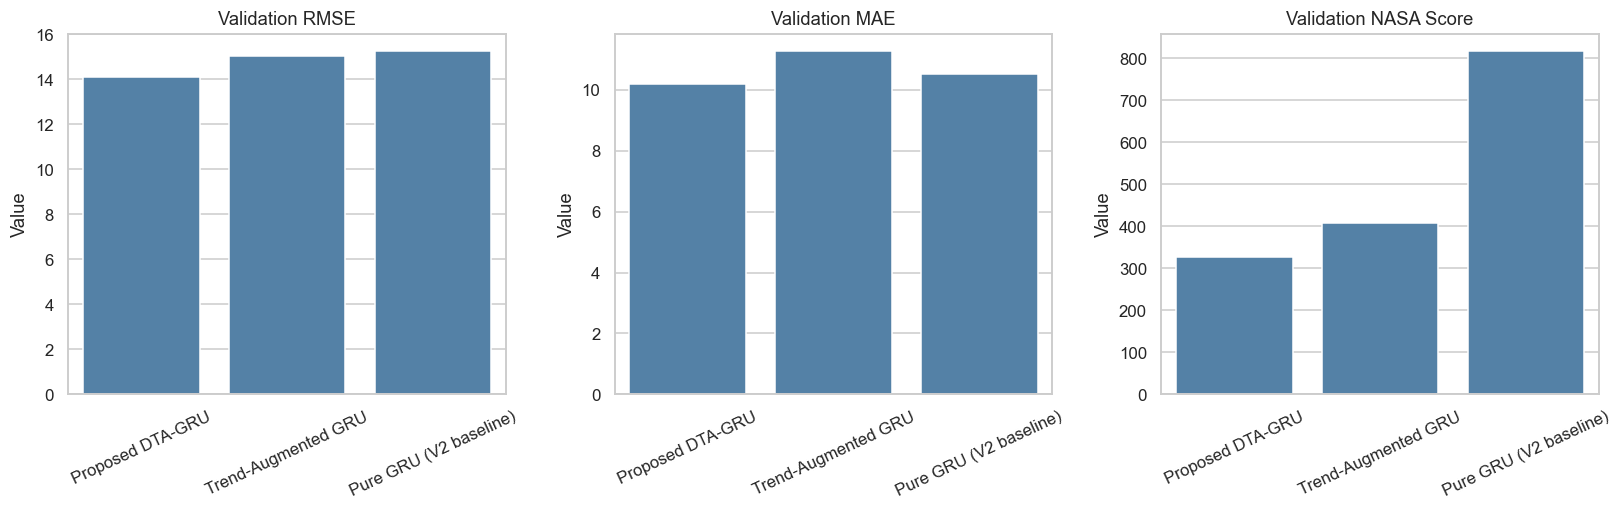

Saved: outputs_DTA_GRU\figures\12_dta_gru_validation_actual_vs_predicted.png


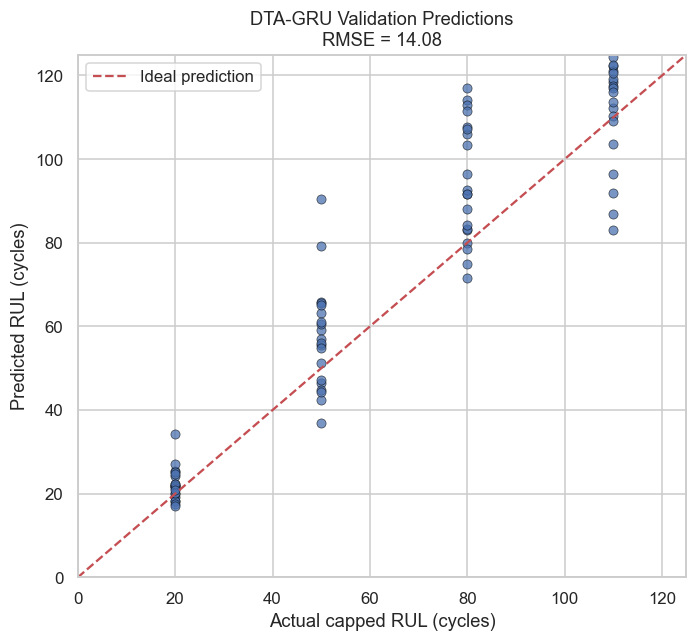

Saved: outputs_DTA_GRU\figures\13_dta_gru_validation_error_distribution.png


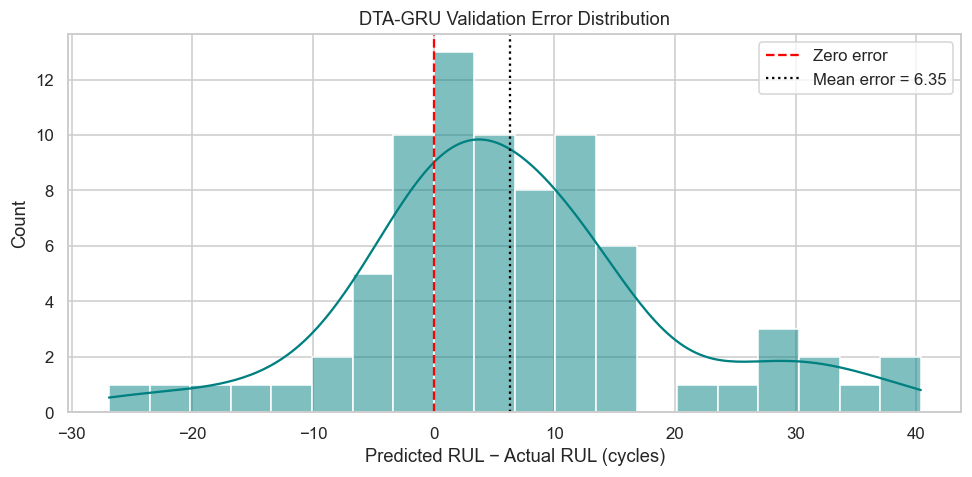

Saved: outputs_DTA_GRU\figures\14_dta_gru_error_by_rul_stage.png


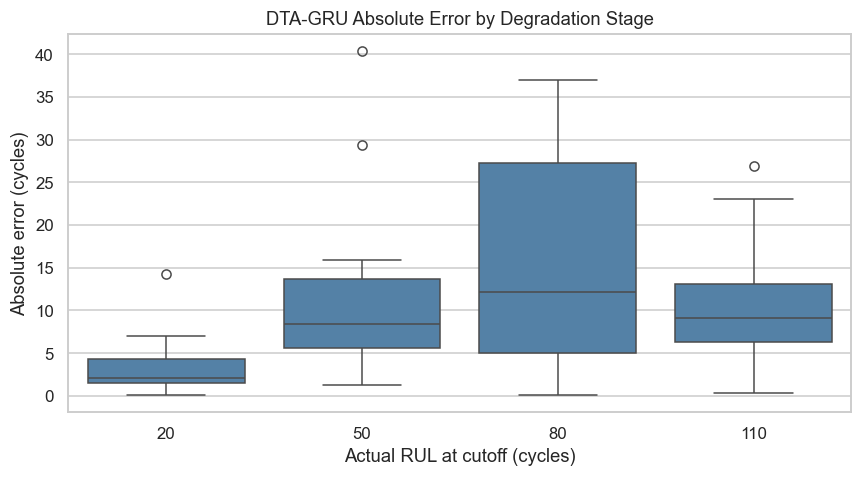

In [13]:
# Figure 10: training loss and validation RMSE for all experiments
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for result in [baseline_result, trend_result, dta_result]:
    hist = result["history"]
    axes[0].plot(hist["epoch"], hist["train_loss"], label=result["name"])
    axes[1].plot(hist["epoch"], hist["val_rmse"], label=result["name"])
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Validation RMSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE (cycles)")
for ax in axes:
    ax.legend(fontsize=8)
save_show(fig, "10_training_curves.png")

# Figure 11: side-by-side validation metrics
metric_names = ["RMSE", "MAE", "NASA Score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
metric_frame = validation_results.melt(id_vars="Model", value_vars=metric_names, var_name="Metric", value_name="Value")
for ax, metric in zip(axes, metric_names):
    subset = metric_frame[metric_frame["Metric"] == metric]
    sns.barplot(data=subset, x="Model", y="Value", color="steelblue", ax=ax)
    ax.set_title(f"Validation {metric}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
save_show(fig, "11_validation_metric_comparison.png")

# Figure 12: actual vs predicted for proposed DTA-GRU
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(dta_result["y_val"], dta_result["val_predictions"], alpha=0.75, edgecolor="black", linewidth=0.4)
ax.plot([0, RUL_CAP], [0, RUL_CAP], "r--", label="Ideal prediction")
ax.set_xlim(0, RUL_CAP)
ax.set_ylim(0, RUL_CAP)
ax.set_xlabel("Actual capped RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.set_title(f"DTA-GRU Validation Predictions\nRMSE = {dta_result['metrics']['RMSE']:.2f}")
ax.legend()
save_show(fig, "12_dta_gru_validation_actual_vs_predicted.png")

# Figure 13: DTA-GRU validation residual distribution
val_error = dta_result["val_predictions"] - dta_result["y_val"]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(val_error, bins=20, kde=True, color="teal", ax=ax)
ax.axvline(0, color="red", linestyle="--", label="Zero error")
ax.axvline(np.mean(val_error), color="black", linestyle=":", label=f"Mean error = {np.mean(val_error):.2f}")
ax.set_title("DTA-GRU Validation Error Distribution")
ax.set_xlabel("Predicted RUL − Actual RUL (cycles)")
ax.set_ylabel("Count")
ax.legend()
save_show(fig, "13_dta_gru_validation_error_distribution.png")

# Figure 14: absolute error by RUL stage
val_plot = dta_result["val_meta"].copy()
val_plot["predicted_RUL"] = dta_result["val_predictions"]
val_plot["absolute_error"] = (val_plot["predicted_RUL"] - val_plot["actual_RUL"]).abs()
val_plot["RUL_stage"] = val_plot["actual_RUL"].astype(int).astype(str)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(
    data=val_plot, x="RUL_stage", y="absolute_error",
    order=[str(x) for x in VALIDATION_RUL_POINTS], color="steelblue", ax=ax
)
ax.set_title("DTA-GRU Absolute Error by Degradation Stage")
ax.set_xlabel("Actual RUL at cutoff (cycles)")
ax.set_ylabel("Absolute error (cycles)")
save_show(fig, "14_dta_gru_error_by_rul_stage.png")

## 14. Official test evaluation — after model decisions are frozen

Refit all three variants on all official training engines, using each model's best validation epoch count. Evaluate on the official test engines once. The official test labels must not be used to select features, loss weights, epochs or model configurations.

In [14]:
def make_final_training_sequences(data, feature_columns, window_size):
    return make_training_sequences(
        data=data,
        units=sorted(data["unit"].unique()),
        feature_columns=feature_columns,
        window_size=window_size
    )


def make_official_test_sequences(data, units, feature_columns, window_size):
    X, used_units = [], []
    for unit in units:
        engine = data[data["unit"] == unit].sort_values("cycle")
        values = engine[feature_columns].to_numpy(dtype=np.float32)
        if len(values) < window_size:
            raise ValueError(f"Test engine {unit} has only {len(values)} cycles (< {window_size}).")
        X.append(values[-window_size:])
        used_units.append(int(unit))
    return np.asarray(X, dtype=np.float32), used_units


def fit_final_model_and_test(result):
    """Refit one experiment on all official training engines and evaluate test engines."""
    seed_everything(SEED)
    feature_columns = result["features"]
    use_dta_loss = result["use_dta_loss"]

    final_imputer = SimpleImputer(strategy="median")
    final_scaler = StandardScaler()
    train_imputed = final_imputer.fit_transform(train_features[feature_columns])
    final_scaler.fit(train_imputed)

    train_scaled = transform_frame(train_features, feature_columns, final_imputer, final_scaler)
    test_scaled = transform_frame(test_features, feature_columns, final_imputer, final_scaler)

    X_full, y_full = make_final_training_sequences(train_scaled, feature_columns, WINDOW_SIZE)
    test_units_sorted = sorted(test_features["unit"].unique())
    X_test, used_test_units = make_official_test_sequences(
        test_scaled, test_units_sorted, feature_columns, WINDOW_SIZE
    )

    y_mean = float(y_full.mean())
    y_std = float(y_full.std() + 1e-8)
    y_full_scaled = (y_full - y_mean) / y_std

    dataset = TensorDataset(
        torch.tensor(X_full, dtype=torch.float32),
        torch.tensor(y_full_scaled, dtype=torch.float32)
    )
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0
    )

    final_model = GRURegressor(input_size=len(feature_columns)).to(device)
    optimizer = torch.optim.Adam(
        final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    custom_loss = DegradationWeightedAsymmetricHuber() if use_dta_loss else None
    epochs_to_train = max(1, int(result["best_epoch"]))
    lr_schedule = result["history"]["lr_used"].to_numpy()[:epochs_to_train]

    for epoch in range(1, epochs_to_train + 1):
        for group in optimizer.param_groups:
            group["lr"] = float(lr_schedule[epoch - 1])
        final_model.train()
        total_loss = 0.0
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad(set_to_none=True)
            predictions = final_model(batch_X)
            if custom_loss is None:
                loss = F.smooth_l1_loss(predictions, batch_y)
            else:
                loss = custom_loss(predictions, batch_y, y_mean, y_std)
            loss.backward()
            nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += float(loss.item())

        if epoch == 1 or epoch == epochs_to_train or epoch % 10 == 0:
            print(f"{result['name']} | final refit epoch {epoch}/{epochs_to_train} | loss={total_loss / len(loader):.4f}")

    final_model.eval()
    with torch.no_grad():
        X_test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)
        test_scaled_predictions = final_model(X_test_tensor).cpu().numpy()

    test_predictions = np.clip(test_scaled_predictions * y_std + y_mean, 0.0, RUL_CAP)
    test_rul_map = dict(zip(test_units_sorted, rul_df["RUL"].astype(float).to_numpy()))
    test_actual_raw = np.asarray([test_rul_map[unit] for unit in used_test_units], dtype=float)
    test_actual_capped = np.minimum(test_actual_raw, RUL_CAP)

    return {
        "name": result["name"],
        "model": final_model,
        "imputer": final_imputer,
        "scaler": final_scaler,
        "feature_columns": feature_columns,
        "target_mean": y_mean,
        "target_std": y_std,
        "test_units": used_test_units,
        "test_actual_raw": test_actual_raw,
        "test_actual_capped": test_actual_capped,
        "test_predictions": test_predictions,
        "test_metrics_capped": evaluate_rul(test_actual_capped, test_predictions),
        "test_metrics_raw": evaluate_rul(test_actual_raw, test_predictions),
        "epochs": epochs_to_train
    }


baseline_test = fit_final_model_and_test(baseline_result)
trend_test = fit_final_model_and_test(trend_result)
dta_test = fit_final_model_and_test(dta_result)

final_test_comparison = pd.DataFrame([
    {"Model": baseline_test["name"], **baseline_test["test_metrics_capped"]},
    {"Model": trend_test["name"], **trend_test["test_metrics_capped"]},
    {"Model": dta_test["name"], **dta_test["test_metrics_capped"]}
]).sort_values("RMSE").reset_index(drop=True)

print("Official test comparison (capped RUL; primary):")
display(final_test_comparison.round(4))

raw_test_comparison = pd.DataFrame([
    {"Model": baseline_test["name"], **baseline_test["test_metrics_raw"]},
    {"Model": trend_test["name"], **trend_test["test_metrics_raw"]},
    {"Model": dta_test["name"], **dta_test["test_metrics_raw"]}
])
print("Official test comparison (raw RUL; supplementary):")
display(raw_test_comparison.round(4))

final_test_comparison.to_csv(OUTPUT_DIR / "official_test_comparison_capped.csv", index=False)
raw_test_comparison.to_csv(OUTPUT_DIR / "official_test_comparison_raw.csv", index=False)

Pure GRU (V2 baseline) | final refit epoch 1/2 | loss=0.1077
Pure GRU (V2 baseline) | final refit epoch 2/2 | loss=0.0543
Trend-Augmented GRU | final refit epoch 1/1 | loss=0.0842
Proposed DTA-GRU | final refit epoch 1/1 | loss=0.1129
Official test comparison (capped RUL; primary):


,Model,RMSE,MAE,NASA Score
0,Pure GRU (V2 baseline),13.6512,9.5795,338.7358
1,Proposed DTA-GRU,14.0807,10.0202,453.4201
2,Trend-Augmented GRU,14.7506,10.4382,570.3626


Official test comparison (raw RUL; supplementary):


,Model,RMSE,MAE,NASA Score
0,Pure GRU (V2 baseline),15.0263,10.6495,377.2649
1,Trend-Augmented GRU,15.6869,11.5082,596.9767
2,Proposed DTA-GRU,15.2150,11.0902,487.0373


## 15. Official test visualizations and export

These plots use the official test labels. Keep them separate from validation figures in the presentation.

,unit,actual_RUL_raw,actual_RUL_capped,predicted_RUL,error,absolute_error
66,67,77.0,77.0,125.000000,48.000000,48.000000
78,79,63.0,63.0,107.406143,44.406143,44.406143
92,93,85.0,85.0,48.944389,-36.055611,36.055611
14,15,83.0,83.0,117.274963,34.274963,34.274963
3,4,82.0,82.0,113.205231,31.205231,31.205231
44,45,114.0,114.0,82.930550,-31.069450,31.069450
97,98,59.0,59.0,89.162842,30.162842,30.162842
15,16,84.0,84.0,110.330795,26.330795,26.330795
95,96,137.0,125.0,99.397324,-25.602676,25.602676
53,54,97.0,97.0,119.841125,22.841125,22.841125


Saved: outputs_DTA_GRU\figures\15_official_test_predictions_and_errors.png


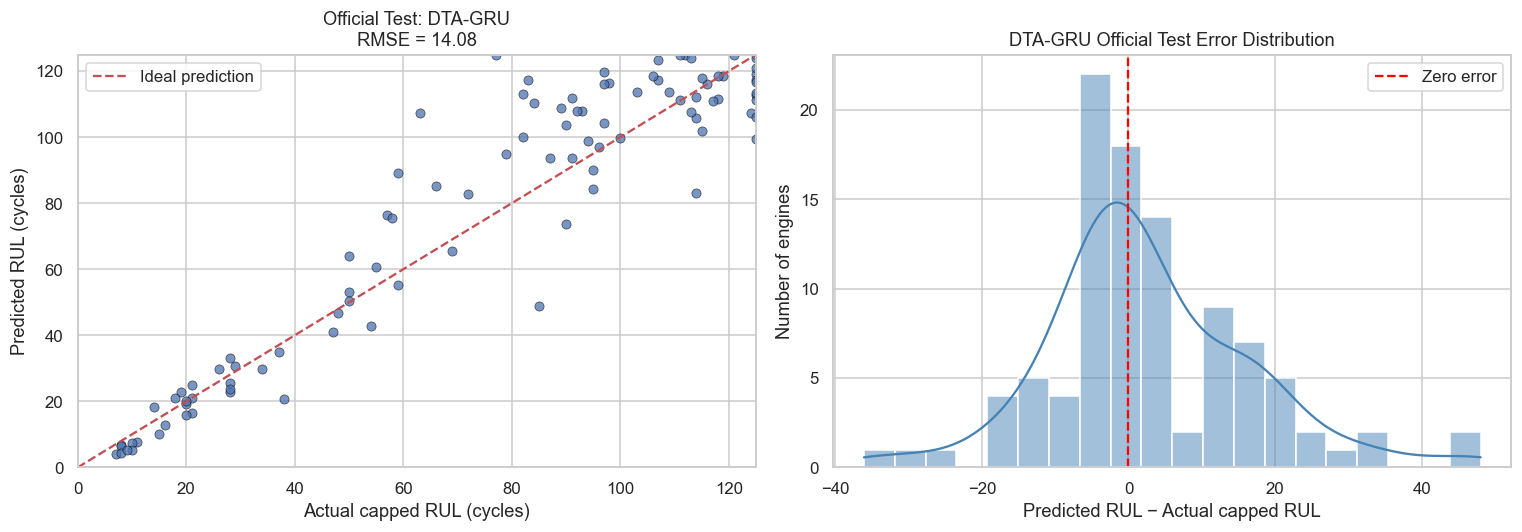

Saved: outputs_DTA_GRU\figures\16_official_test_metric_comparison.png


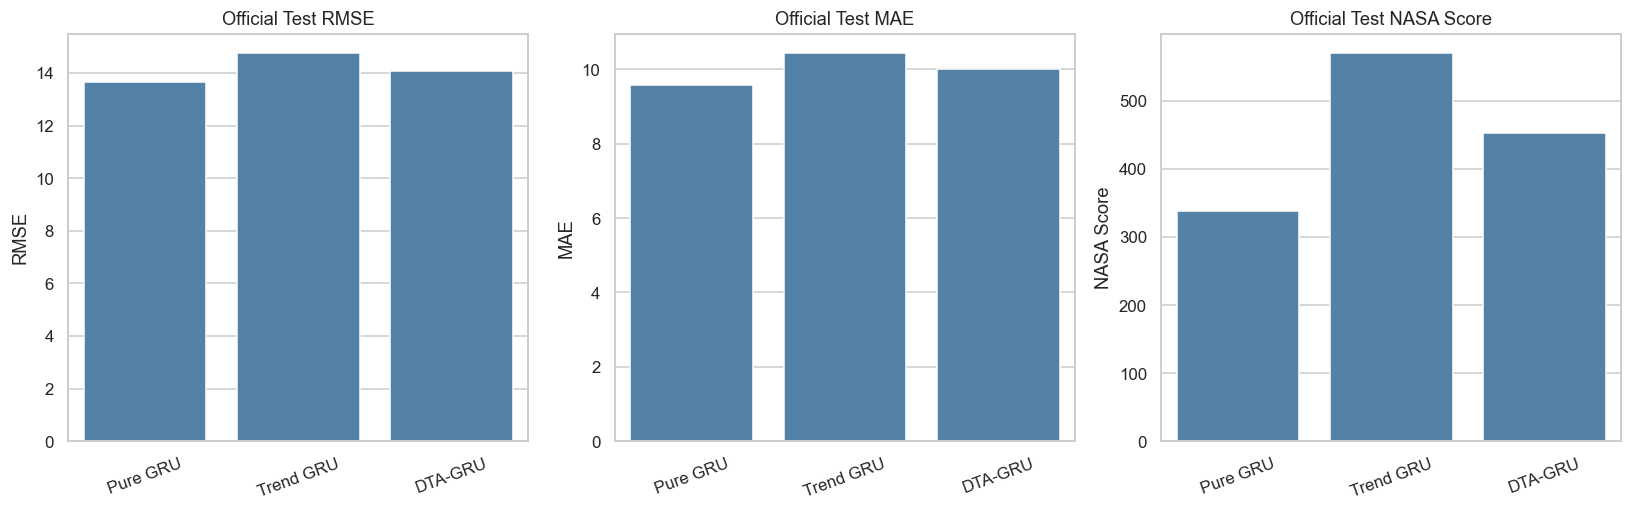


Saved outputs under: D:\ML_project\outputs_DTA_GRU
- figures/                        presentation-ready PNG plots
- validation_model_comparison.csv
- official_test_comparison_capped.csv
- dta_gru_official_test_predictions.csv
- dta_gru_fd001.pt
- dta_gru_preprocessing.joblib
- dta_gru_metadata.json


In [15]:
# Official test prediction table for the proposed model
test_results = pd.DataFrame({
    "unit": dta_test["test_units"],
    "actual_RUL_raw": dta_test["test_actual_raw"],
    "actual_RUL_capped": dta_test["test_actual_capped"],
    "predicted_RUL": dta_test["test_predictions"]
})
test_results["error"] = test_results["predicted_RUL"] - test_results["actual_RUL_capped"]
test_results["absolute_error"] = test_results["error"].abs()
display(test_results.sort_values("absolute_error", ascending=False).head(15))

# Figure 15: official test actual vs predicted for DTA-GRU
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test_results["actual_RUL_capped"], test_results["predicted_RUL"], alpha=0.75, edgecolor="black", linewidth=0.4)
axes[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--", label="Ideal prediction")
axes[0].set_xlim(0, RUL_CAP)
axes[0].set_ylim(0, RUL_CAP)
axes[0].set_xlabel("Actual capped RUL (cycles)")
axes[0].set_ylabel("Predicted RUL (cycles)")
axes[0].set_title(f"Official Test: DTA-GRU\nRMSE = {dta_test['test_metrics_capped']['RMSE']:.2f}")
axes[0].legend()
sns.histplot(test_results["error"], bins=20, kde=True, color="steelblue", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", label="Zero error")
axes[1].set_title("DTA-GRU Official Test Error Distribution")
axes[1].set_xlabel("Predicted RUL − Actual capped RUL")
axes[1].set_ylabel("Number of engines")
axes[1].legend()
save_show(fig, "15_official_test_predictions_and_errors.png")

# Figure 16: compare all three models on official test metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, metric in zip(axes, ["RMSE", "MAE", "NASA Score"]):
    values = [
        baseline_test["test_metrics_capped"][metric],
        trend_test["test_metrics_capped"][metric],
        dta_test["test_metrics_capped"][metric]
    ]
    sns.barplot(x=["Pure GRU", "Trend GRU", "DTA-GRU"], y=values, color="steelblue", ax=ax)
    ax.set_title(f"Official Test {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=20)
save_show(fig, "16_official_test_metric_comparison.png")

# Export model and preprocessing needed for proposed DTA-GRU inference
torch.save({
    "model_state_dict": dta_test["model"].state_dict(),
    "model_name": "DTA-GRU",
    "input_size": len(dta_test["feature_columns"]),
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "window_size": WINDOW_SIZE,
    "feature_columns": dta_test["feature_columns"],
    "raw_sensors": baseline_sensors,
    "velocity_window": 5,
    "rul_cap": RUL_CAP,
    "subset": SUBSET
}, OUTPUT_DIR / "dta_gru_fd001.pt")

joblib.dump({
    "imputer": dta_test["imputer"],
    "scaler": dta_test["scaler"],
    "target_mean": dta_test["target_mean"],
    "target_std": dta_test["target_std"],
    "feature_columns": dta_test["feature_columns"],
    "raw_sensors": baseline_sensors,
    "velocity_window": 5,
    "window_size": WINDOW_SIZE,
    "rul_cap": RUL_CAP
}, OUTPUT_DIR / "dta_gru_preprocessing.joblib")

test_results.to_csv(OUTPUT_DIR / "dta_gru_official_test_predictions.csv", index=False)

metadata = {
    "subset": SUBSET,
    "proposed_model": "DTA-GRU",
    "baseline_model": "Pure GRU V2",
    "raw_sensors": baseline_sensors,
    "proposed_features": proposed_features,
    "window_size": WINDOW_SIZE,
    "rul_cap": RUL_CAP,
    "validation_rul_points": VALIDATION_RUL_POINTS,
    "baseline_validation_metrics": baseline_result["metrics"],
    "trend_validation_metrics": trend_result["metrics"],
    "dta_validation_metrics": dta_result["metrics"],
    "baseline_test_metrics_capped": baseline_test["test_metrics_capped"],
    "trend_test_metrics_capped": trend_test["test_metrics_capped"],
    "dta_test_metrics_capped": dta_test["test_metrics_capped"],
    "baseline_best_epoch": baseline_result["best_epoch"],
    "trend_best_epoch": trend_result["best_epoch"],
    "dta_best_epoch": dta_result["best_epoch"],
    "loss_parameters": {
        "late_life_boost": 0.50,
        "gamma": 1.0,
        "overprediction_weight": 1.25
    }
}
with open(OUTPUT_DIR / "dta_gru_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("\nSaved outputs under:", OUTPUT_DIR.resolve())
print("- figures/                        presentation-ready PNG plots")
print("- validation_model_comparison.csv")
print("- official_test_comparison_capped.csv")
print("- dta_gru_official_test_predictions.csv")
print("- dta_gru_fd001.pt")
print("- dta_gru_preprocessing.joblib")
print("- dta_gru_metadata.json")

## 16. How to present the method and interpret the results

### Suggested explanation

> We initially implemented TCN/CNN, GRU and BiLSTM architectures. GRU was our strongest initial baseline, so we retained its architecture rather than making the recurrent network more complex. We observed that our existing GRU consumed raw sensor sequences even though our feature-engineering stage already calculated sensor differences and rolling trends. We therefore proposed DTA-GRU: a causal degradation-velocity representation that appends a five-cycle smoothed sensor derivative to each original sensor channel. We also tested a mild late-life-weighted asymmetric Smooth-L1 objective to reflect the greater operational cost of overestimating remaining useful life. We conducted an ablation with pure GRU, trend-only GRU and the complete DTA-GRU.

### What to report

- Validation and official test RMSE, MAE and NASA Score for all three experiments.
- Whether trend augmentation alone helped.
- Whether the loss function added further improvement.
- The actual-vs-predicted plot and error-by-RUL-stage plot.

### Limitations

- The proposed method is a hypothesis and may not beat the baseline on every metric.
- A single FD001 split is not sufficient to establish broad generalization. Repeat experiments with multiple seeds or engine-level folds before making strong claims.
- The loss weights are fixed design choices here; tuning them on the official test set is not allowed.
- Do not say DTA-GRU is superior unless the measured results support that statement.

### Presentation figure checklist

1. `01_engine_life_and_rul_distribution.png` — dataset and target overview.
2. `02_piecewise_rul_target.png` — RUL target construction.
3. `03_sensor_correlation_heatmap.png` — sensor relationships.
4. `04_sensor_variability.png` — sensor variability.
5. `05_sensor_feature_engineering_example.png` — raw, smoothed and velocity signals.
6. `06_sensor_velocity_magnitude.png` and `07_raw_and_velocity_channels.png` — proposed input features.
7. `10_training_curves.png` and `11_validation_metric_comparison.png` — ablation evidence.
8. `12_dta_gru_validation_actual_vs_predicted.png` and `14_dta_gru_error_by_rul_stage.png` — validation diagnostics.
9. `15_official_test_predictions_and_errors.png` and `16_official_test_metric_comparison.png` — final test results.